<a href="https://colab.research.google.com/github/agungstiawan-02/analisis-ulasan-bank-digital/blob/main/analisis_ulasan_bank_digital.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
!unzip -o archive.zip

Archive:  archive.zip
  inflating: review_ALADIN_ALL.csv   
  inflating: review_BEYOND_ALL.csv   
  inflating: review_JAGO_ALL.csv     


In [26]:
import pandas as pd

files = {
    "Aladin": "review_ALADIN_ALL.csv",
    "BYOND": "review_BEYOND_ALL.csv",
    "Jago": "review_JAGO_ALL.csv",
}

frames = []
for app, path in files.items():
    df = pd.read_csv(path)
    df["app"] = app
    frames.append(df)

reviews = pd.concat(frames, ignore_index=True)
reviews = reviews.drop(columns=["userName", "userImage"])
reviews["at"] = pd.to_datetime(reviews["at"])

In [27]:
print(reviews.shape)
reviews.info()
print(reviews.isna().sum())
print(reviews.groupby("app")["at"].agg(["min", "max", "count"]))
print("duplikat reviewId:", reviews.duplicated(subset=["reviewId"]).sum())
print("duplikat isi ulasan per aplikasi:", reviews.duplicated(subset=["app", "content"]).sum())

(155967, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 155967 entries, 0 to 155966
Data columns (total 10 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   reviewId              155967 non-null  object        
 1   content               155967 non-null  object        
 2   score                 155967 non-null  int64         
 3   thumbsUpCount         155967 non-null  int64         
 4   reviewCreatedVersion  124756 non-null  object        
 5   at                    155967 non-null  datetime64[ns]
 6   replyContent          138797 non-null  object        
 7   repliedAt             138797 non-null  object        
 8   appVersion            124756 non-null  object        
 9   app                   155967 non-null  object        
dtypes: datetime64[ns](1), int64(2), object(7)
memory usage: 11.9+ MB
reviewId                    0
content                     0
score                       0
thumbsUp

In [28]:
dup = reviews[reviews.duplicated(subset=["app", "content"], keep=False)]
print(dup.groupby("app").size())
print(dup.groupby(["app", "content"]).size().sort_values(ascending=False).head(20))

app
Aladin     2723
BYOND      4154
Jago      17671
dtype: int64
app     content        
Jago    Mantap             1362
        mantap             1254
        Ok                 1034
        Bagus               838
        bagus               722
        Good                626
        ok                  536
        good                451
Aladin  Mantap              287
BYOND   bagus               265
Aladin  Bagus               245
        Ok                  239
Jago    keren               238
        Keren               225
        sangat membantu     223
        Oke                 215
        sangat bagus        210
        Sangat membantu     209
BYOND   mantap              201
Jago    oke                 169
dtype: int64


In [29]:
reviews["n_words"] = reviews["content"].str.split().str.len()
print(reviews["n_words"].describe())
print((reviews["n_words"] <= 2).groupby(reviews["app"]).mean().round(3))

count    155967.000000
mean         13.242712
std          13.568990
min           1.000000
25%           4.000000
50%           9.000000
75%          18.000000
max         115.000000
Name: n_words, dtype: float64
app
Aladin    0.118
BYOND     0.093
Jago      0.310
Name: n_words, dtype: float64


In [30]:
reviews["content_clean"] = reviews["content"].str.lower().str.strip()
reviews["is_short"] = reviews["n_words"] <= 2
print(reviews["is_short"].sum(), "ulasan pendek dari", len(reviews))

30122 ulasan pendek dari 155967


In [31]:
print(reviews.groupby("app")["score"].agg(["mean", "count"]).round(2))
print(pd.crosstab(reviews["app"], reviews["score"], normalize="index").round(3))
print(reviews.groupby("is_short")["score"].mean().round(2))

        mean  count
app                
Aladin  4.25  30243
BYOND   3.09  57005
Jago    3.77  68719
score       1      2      3      4      5
app                                      
Aladin  0.140  0.029  0.032  0.032  0.766
BYOND   0.386  0.074  0.059  0.030  0.451
Jago    0.243  0.038  0.045  0.054  0.620
is_short
False    3.41
True     4.46
Name: score, dtype: float64


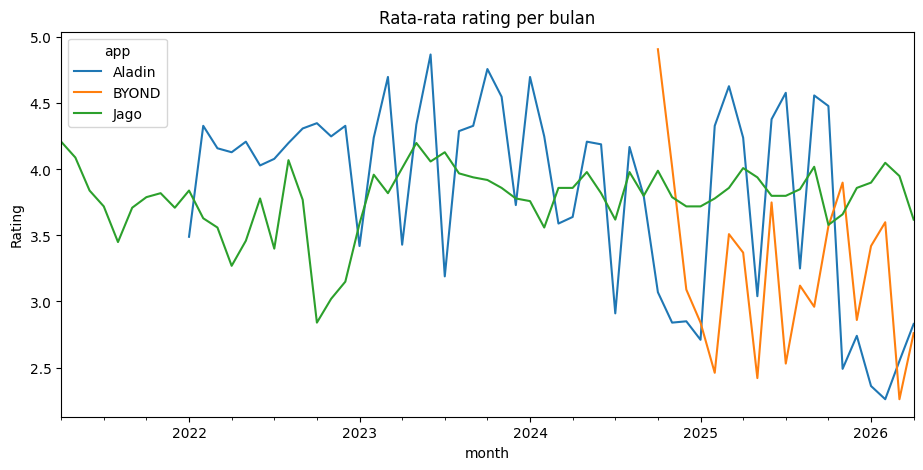

In [32]:
import matplotlib.pyplot as plt

reviews["month"] = reviews["at"].dt.to_period("M").dt.to_timestamp()
monthly = reviews.groupby(["month", "app"])["score"].mean().unstack().round(2)

monthly.plot(figsize=(11, 5), title="Rata-rata rating per bulan")
plt.ylabel("Rating")
plt.show()

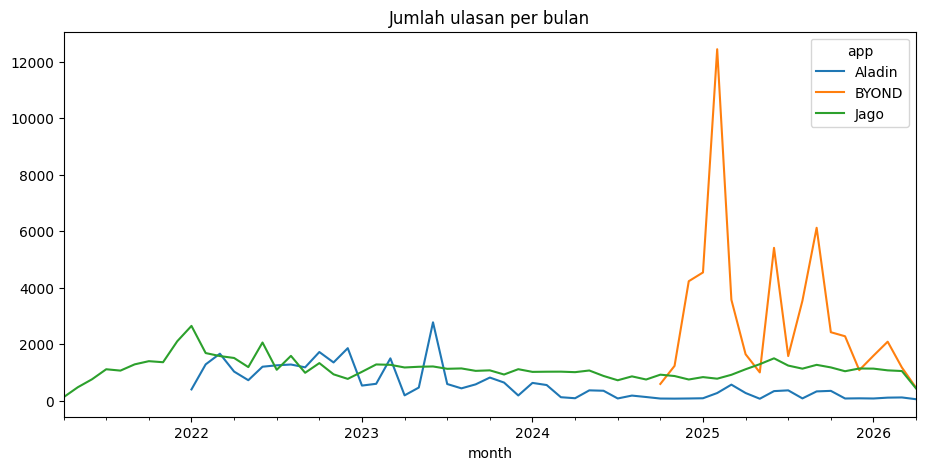

In [33]:
counts = reviews.groupby(["month", "app"]).size().unstack()
counts.plot(figsize=(11, 5), title="Jumlah ulasan per bulan")
plt.show()

In [34]:
import sqlite3

conn = sqlite3.connect(":memory:")
sql_df = reviews[["reviewId", "app", "score", "at", "n_words", "is_short"]].copy()
sql_df["at"] = sql_df["at"].astype(str)
sql_df["has_reply"] = reviews["replyContent"].notna().astype(int)
sql_df.to_sql("reviews", conn, index=False)

155967

In [35]:
query = """
SELECT app,
       COUNT(*) AS total_reviews,
       ROUND(AVG(score), 2) AS avg_score,
       ROUND(100.0 * SUM(CASE WHEN score = 1 THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_1star,
       ROUND(100.0 * SUM(has_reply) / COUNT(*), 1) AS pct_replied
FROM reviews
GROUP BY app
ORDER BY avg_score DESC
"""
pd.read_sql(query, conn)

,app,total_reviews,avg_score,pct_1star,pct_replied
0,Aladin,30243,4.25,14.0,86.6
1,Jago,68719,3.77,24.3,81.4
2,BYOND,57005,3.09,38.6,99.5


In [36]:
# Sel A: baca langsung ulasan bintang 1 BYOND di Februari 2025
feb = reviews[
    (reviews["app"] == "BYOND")
    & (reviews["at"].dt.to_period("M") == "2025-02")
    & (reviews["score"] == 1)
    & (~reviews["is_short"])
]
print(len(feb))
print(feb["content_clean"].sample(15, random_state=1).to_string())

6130
68028    lemot, lagi ada perlu malah gabisa narik, load...
70554                              apa ni apk nya gajelas,
68935                    amat sangat jelek setelah beralih
68188    aplikasi baru. pas ke bank bsi admin² pada sur...
71399                   ga jelas byond selalu gangguan ...
69274    saat login mau transfer, aplikasi ke log out s...
65544     aplikasih sering error...mending pake versi lama
69293    kalo gak niat bikin aplikasi jangan nyusahin n...
67308    aplikasi rusak, bisa-bisa ny gabisa kirim resi...
69796    aplikasi gagal,,loading teruss sekali bisa buk...
68637    sering terjadi gangguan, saat ini jga sdg gang...
73060    aplikasi terburuk, kalau memang belum siap jan...
65944                         aplikasi eror mulu gak jelas
67973                  loadingnya lama dan sering gangguan
76376    aplikasi jelek, sok sok an ngikut ngikut wondr...


In [37]:
# Sel B: kata yang paling sering muncul di ulasan bintang 1 per aplikasi
from collections import Counter
import re

stop = set("yang dan di ke dari ini itu untuk dengan tidak ga gak nggak saya aplikasi apk aja banget bisa sudah udah atau jadi karena tapi ada pada mau kok sih yg tp dg dr jd".split())

def top_words(df, n=20):
    words = re.findall(r"[a-z]+", " ".join(df["content_clean"]))
    return Counter(w for w in words if w not in stop and len(w) > 2).most_common(n)

for app in ["Aladin", "BYOND", "Jago"]:
    sub = reviews[(reviews["app"] == app) & (reviews["score"] == 1) & (~reviews["is_short"])]
    print(app, len(sub))
    print(top_words(sub))
    print()

Aladin 3906
[('nya', 1004), ('aladin', 721), ('masuk', 602), ('bank', 529), ('saldo', 516), ('daftar', 499), ('terus', 393), ('padahal', 386), ('verifikasi', 377), ('lagi', 362), ('email', 356), ('wajah', 346), ('susah', 335), ('tolong', 326), ('gagal', 312), ('data', 292), ('hari', 289), ('juga', 281), ('buka', 277), ('kenapa', 276)]

BYOND 20495
[('bsi', 5462), ('nya', 4353), ('sering', 3814), ('byond', 3228), ('transaksi', 3161), ('terus', 2728), ('lagi', 2643), ('lama', 2559), ('malah', 2484), ('bank', 2123), ('gagal', 2058), ('mobile', 1906), ('tolong', 1894), ('susah', 1884), ('error', 1858), ('gangguan', 1856), ('selalu', 1837), ('hari', 1819), ('eror', 1817), ('sangat', 1804)]

Jago 15483
[('jago', 4685), ('bank', 3691), ('nya', 3559), ('akun', 2976), ('login', 2934), ('masuk', 2835), ('padahal', 2025), ('saldo', 1903), ('uang', 1603), ('malah', 1602), ('lagi', 1587), ('data', 1552), ('email', 1549), ('sama', 1469), ('tolong', 1409), ('buat', 1351), ('daftar', 1315), ('salah', 

In [38]:
categories = {
    "Error/gangguan": ["error", "eror", "bug", "gangguan", "gagal", "crash", "force close"],
    "Lambat/loading": ["lemot", "lambat", "loading", "load"],
    "Login/akses": ["login", "log in", "masuk", "logout", "log out", "keluar sendiri"],
    "Transaksi/saldo": ["transaksi", "transfer", "saldo", "tarik"],
    "Registrasi/verifikasi": ["daftar", "registrasi", "verifikasi", "ktp"],
}

low = reviews[(reviews["score"] == 1) & (~reviews["is_short"])]
rows = {}
for name, kws in categories.items():
    pat = "|".join(kws)
    rows[name] = low.groupby("app")["content_clean"].apply(
        lambda s: round(s.str.contains(pat, regex=True).mean() * 100, 1)
    )
pd.DataFrame(rows).T

app,Aladin,BYOND,Jago
Error/gangguan,14.8,34.6,9.4
Lambat/loading,7.2,12.3,7.2
Login/akses,20.8,17.5,33.6
Transaksi/saldo,19.4,22.6,18.6
Registrasi/verifikasi,24.5,6.1,18.2


In [39]:
byond = reviews[reviews["app"] == "BYOND"].copy()
byond["migrasi"] = byond["content_clean"].str.contains("beralih|versi lama|aplikasi baru|bsi mobile|pindah", regex=True)
print(byond.groupby(byond["at"].dt.to_period("M"))["migrasi"].mean().mul(100).round(1))

at
2024-10    1.2
2024-11    5.2
2024-12    9.7
2025-01    9.6
2025-02    9.2
2025-03    6.5
2025-04    6.2
2025-05    8.1
2025-06    3.5
2025-07    6.0
2025-08    3.8
2025-09    3.3
2025-10    2.9
2025-11    1.9
2025-12    2.5
2026-01    2.7
2026-02    2.0
2026-03    4.1
2026-04    4.4
Freq: M, Name: migrasi, dtype: float64


In [40]:
byond = reviews[reviews["app"] == "BYOND"]
ver = byond.groupby("appVersion")["score"].agg(["count", "mean"]).round(2)
ver[ver["count"] >= 500].sort_index()

,count,mean
appVersion,,
1.0.1,659,4.90
1.0.2,1410,3.59
1.0.3,5761,2.98
1.0.4,14701,2.61
1.0.5,6645,3.59
1.1.0,3068,2.42
1.1.2,7104,3.14
1.2.0,1332,3.90
1.2.1,4415,3.56


In [41]:
low_b = byond[(byond["score"] == 1) & (~byond["is_short"])].copy()
low_b["month"] = low_b["at"].dt.to_period("M")
low_b["loading"] = low_b["content_clean"].str.contains("lemot|lambat|loading|load")
low_b.groupby("month")["loading"].mean().mul(100).round(1)

,loading
month,
2024-10,0.0
2024-11,8.5
2024-12,7.8
2025-01,12.3
2025-02,13.3
2025-03,10.3
2025-04,12.0
2025-05,10.9
2025-06,17.4
